# Project Title:
Iris Flower Classification Using Machine Learning

# Introduction:
In this project, I am going to build a Machine Learning model that can identify different types of Iris flowers. There are three types of flowers in this dataset: Setosa, Versicolor, and Virginica.

I will use four measurements of each flower: sepal length, sepal width, petal length, and petal width. Using these measurements, I will train a classification model with Python and Scikit-learn to predict the flower species.

Through this project, I want to understand how Machine Learning works and how a model learns from data to make predictions.

# Objective of the project:
1. To understand and explore the Iris flower dataset.
2. To identify the important features used for flower classification.
3. To prepare the dataset for Machine Learning.
4. To train a classification model using Scikit-learn.
5. To test the model and check its accuracy.
6. To predict the species of a new Iris flower using its measurements.

In [ ]:
#Importing a Python Libarary and loading an Iris Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
#checking a shape of the dataset
df.shape

(150, 6)

In [ ]:
#checking column names of the dataset
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [ ]:
#checking the information of the Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
#checking an statics information  of the Data
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


# Data Cleaning

In [ ]:
#checking missing values in the Dataset
df.isnull().sum()

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [ ]:
#Checking duplicate Value in the Dataset
df.duplicated().sum()

np.int64(0)

In [ ]:
#Checking Value count in the species column
df['Species'].value_counts()

,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


# Data visualization

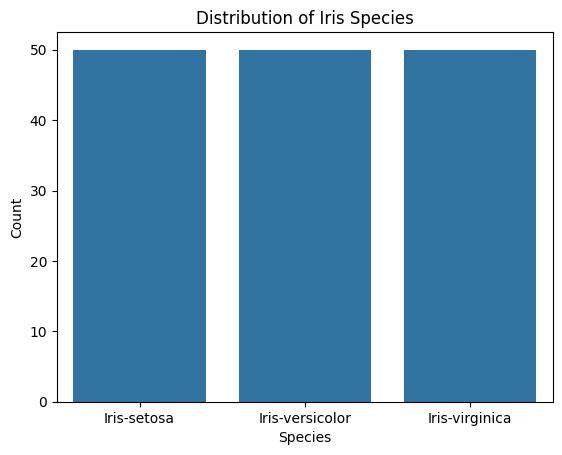

In [ ]:
#Creating a countplot to checking the distribution of iris species
sns.countplot(x='Species', data=df)

plt.title('Distribution of Iris Species')
plt.xlabel('Species')
plt.ylabel('Count')
plt.show()

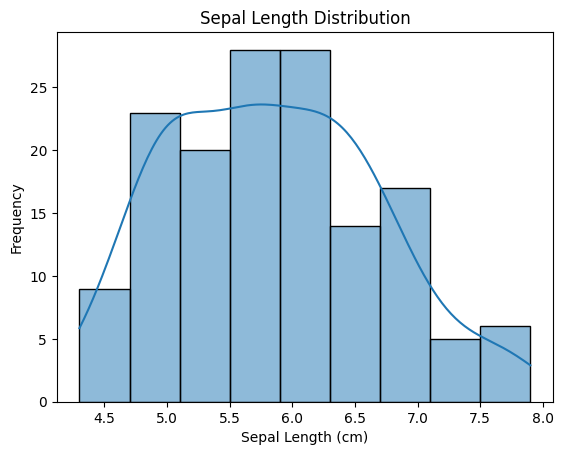

In [ ]:
#Creating a histplot to observe the sepal length distribution
sns.histplot(data=df, x='SepalLengthCm', kde=True)

plt.title('Sepal Length Distribution')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Frequency')
plt.show()

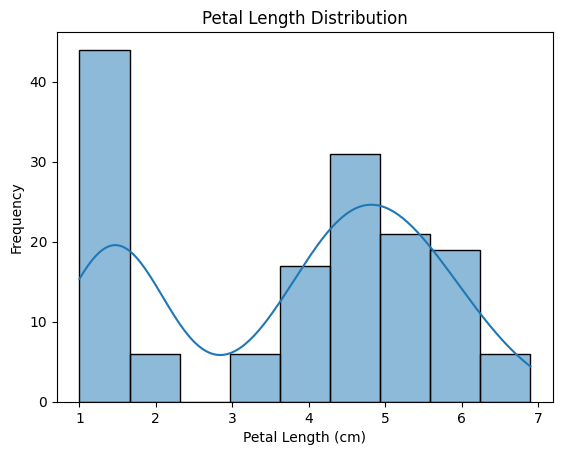

In [ ]:
#Creating a histplot to observe petal length distribution of the iris dataset
sns.histplot(data=df, x='PetalLengthCm', kde=True)

plt.title('Petal Length Distribution')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Frequency')
plt.show()

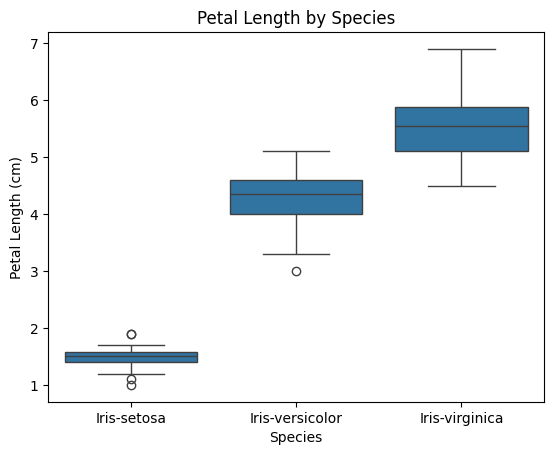

In [ ]:
#Creating a Boxplot to compare between iris-setosa,irisversiacolour,irisvirginca
sns.boxplot(data=df, x='Species', y='PetalLengthCm')

plt.title('Petal Length by Species')
plt.xlabel('Species')
plt.ylabel('Petal Length (cm)')
plt.show()

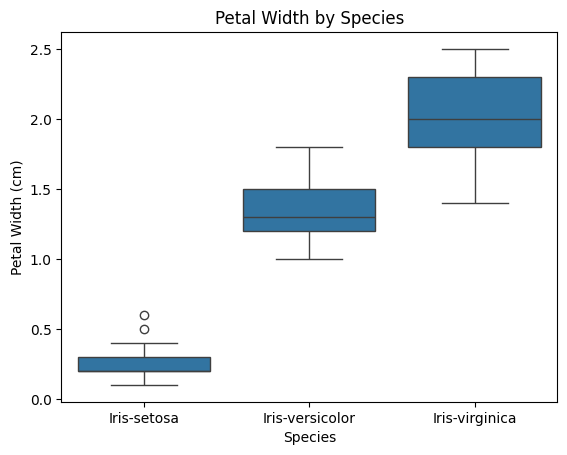

In [ ]:
#creating a boxplot to compare petal width by sepecies
sns.boxplot(data=df, x='Species', y='PetalWidthCm')

plt.title('Petal Width by Species')
plt.xlabel('Species')
plt.ylabel('Petal Width (cm)')
plt.show()

In [ ]:
#if species column was object datatype then we did not include in the features columns then this was a different target column of predication of the model
X = df.drop('Species', axis=1)

y = df['Species']

In [ ]:
# we check our feature columns and Target columns
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0   1            5.1           3.5            1.4           0.2
1   2            4.9           3.0            1.4           0.2
2   3            4.7           3.2            1.3           0.2
3   4            4.6           3.1            1.5           0.2
4   5            5.0           3.6            1.4           0.2

Target:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object


In [ ]:
#importing a sklearn library to training and testing of the machine learning model
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
#checking Training and testing data shape
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 5)
Testing Data: (30, 5)


In [ ]:
#import a sklearn library to import a logistic regression model algorithm
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=200)

In [ ]:
#checking a predication values of the train model
y_pred = model.predict(X_test)
print("Predicted Values:")
print(y_pred)

Predicted Values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']


In [ ]:
#checking actual species vs model predicted species
comparison = pd.DataFrame({
    'Actual Species': y_test.values,
    'Predicted Species': y_pred
})

comparison.head(10)

,Actual Species,Predicted Species
0,Iris-setosa,Iris-setosa
1,Iris-virginica,Iris-virginica
2,Iris-versicolor,Iris-versicolor
3,Iris-versicolor,Iris-versicolor
4,Iris-setosa,Iris-setosa
5,Iris-versicolor,Iris-versicolor
6,Iris-setosa,Iris-setosa
7,Iris-setosa,Iris-setosa
8,Iris-virginica,Iris-virginica
9,Iris-versicolor,Iris-versicolor


In [ ]:
#importing a sklearn library to checking a accuracy score of the machine learing nmodel
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


In [ ]:
#Using  a confusion metrix to check predications data are correct or not
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


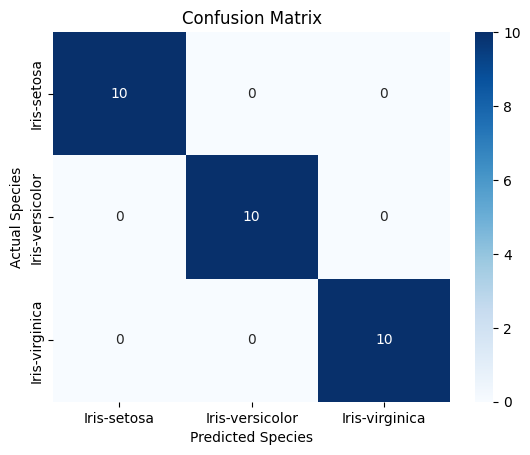

In [ ]:
#Creating an heatmap to check confusion matrix in the dataset
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_,
            yticklabels=model.classes_)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

In [ ]:
#importing a sklearn library to import a classification report to check precision recall and f1 score of the confusion matrix of the machine learning model
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



#Conclusion:

In this project, I developed a Machine Learning model to classify Iris flowers into three species: Setosa, Versicolor, and Virginica.

I used the Iris dataset downloaded from Kaggle and performed data exploration and visualization. I checked missing values and duplicate records to ensure data quality.

I used Logistic Regression as the classification algorithm and split the dataset into 80% training data and 20% testing data.

The model achieved 100% accuracy on the test dataset. I also evaluated its performance using a Confusion Matrix and Classification Report.

This project helped me understand basic Machine Learning concepts such as classification, training, testing, prediction, and model evaluation.